<a href="https://colab.research.google.com/github/2004sreedevip/ML-Lab-/blob/main/AML_Lab_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#a
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#load dataset
df = pd.read_csv("student-mat.csv", sep=";")

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [ ]:
#checking the dataset dimensions

print("Dimensions:", df.shape)


Dimensions: (395, 33)


In [ ]:
#checking the datatypes

print(df.dtypes)


school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [ ]:
#checking the missing values

print(df.isnull().sum())


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [ ]:
#checking duplicate records

print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [ ]:
#b

cols = ["studytime", "absences", "G3"]

for col in cols:
    x = df[col]

    print("\nColumn:", col)
    print("Mean:", np.mean(x))
    print("Median:", np.median(x))
    print("Standard Deviation:", np.std(x))


Column: studytime
Mean: 2.0354430379746837
Median: 2.0
Standard Deviation: 0.8381773436532131

Column: absences
Mean: 5.708860759493671
Median: 4.0
Standard Deviation: 7.992958766400057

Column: G3
Mean: 10.415189873417722
Median: 11.0
Standard Deviation: 4.575639641460531


In [ ]:
x = df["absences"]

Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = x[(x < lower) | (x > upper)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Outlier Count:", len(outliers))
print("Outlier Values:", outliers.tolist())

Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower Bound: -12.0
Upper Bound: 20.0
Outlier Count: 15
Outlier Values: [25, 54, 26, 56, 24, 28, 22, 21, 75, 22, 30, 38, 22, 40, 23]


In [ ]:
#c

avg_grade = df.groupby("studytime")["G3"].mean()

print(avg_grade)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


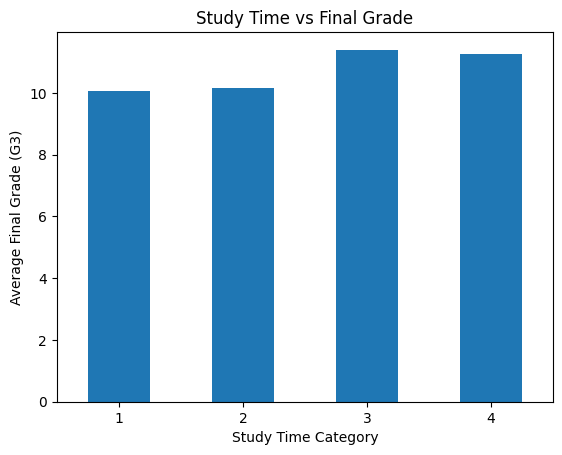

In [ ]:
avg_grade.plot(kind="bar")

plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade (G3)")
plt.title("Study Time vs Final Grade")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#d
def analyze_column(col):
    x = df[col].dropna()

    stats = x.describe()

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = x[(x < lower) | (x > upper)]

    return stats, len(outliers), outliers.tolist()

In [ ]:
stats1, count1, values1 = analyze_column("absences")
stats2, count2, values2 = analyze_column("G3")

results = pd.DataFrame({
    "Absences": stats1,
    "G3": stats2
})

print("Descriptive Statistics:")
print(results.round(2))

print("\nOutlier Count:")
print("Absences:", count1)
print("G3:", count2)

print("\nOutlier Values:")
print("Absences:", values1)
print("G3:", values2)

Descriptive Statistics:
       Absences      G3
count    395.00  395.00
mean       5.71   10.42
std        8.00    4.58
min        0.00    0.00
25%        0.00    8.00
50%        4.00   11.00
75%        8.00   14.00
max       75.00   20.00

Outlier Count:
Absences: 15
G3: 0

Outlier Values:
Absences: [25, 54, 26, 56, 24, 28, 22, 21, 75, 22, 30, 38, 22, 40, 23]
G3: []


In [ ]:
print("Minimum G3:", df["G3"].min())
print("Maximum G3:", df["G3"].max())
print("Number of zero grades:", (df["G3"] == 0).sum())

Minimum G3: 0
Maximum G3: 20
Number of zero grades: 38
